In [1]:
import pandas as pd
from sklearn.datasets import load_breast_cancer

# Cargar el dataset
datos = load_breast_cancer(as_frame=True)
df = datos.frame

# Mostrar información general
print("Dimensiones:", df.shape)
print("Valores nulos:", df.isnull().sum().sum())
print("Duplicados:", df.duplicated().sum())

display(df.head())


Dimensiones: (569, 31)
Valores nulos: 0
Duplicados: 0


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [2]:
import os

# Crear carpetas
os.makedirs("datos/datos_ini", exist_ok=True)
os.makedirs("datos/datos_limp", exist_ok=True)

# Guardar datos originales
df.to_csv("datos/datos_ini/dataset.csv", index=False)

# Limpiar datos
df_limpio = df.drop_duplicates().copy()
df_limpio = df_limpio.dropna()

# Guardar datos limpios
df_limpio.to_csv("datos/datos_limp/dataset_limpio.csv", index=False)

print("Registros originales:", len(df))
print("Registros limpios:", len(df_limpio))
print("Duplicados eliminados:", len(df) - len(df.drop_duplicates()))
print("Valores nulos restantes:", df_limpio.isnull().sum().sum())


Registros originales: 569
Registros limpios: 569
Duplicados eliminados: 0
Valores nulos restantes: 0


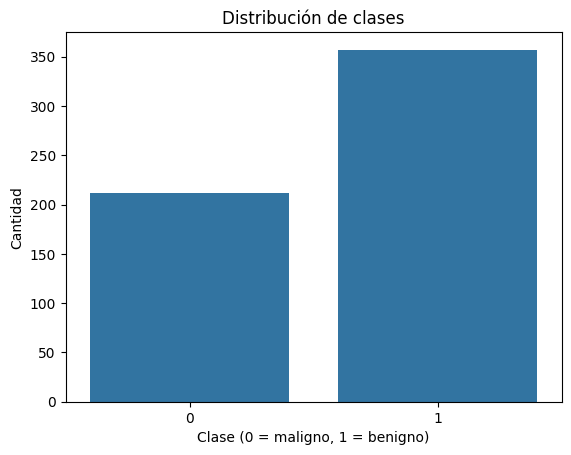

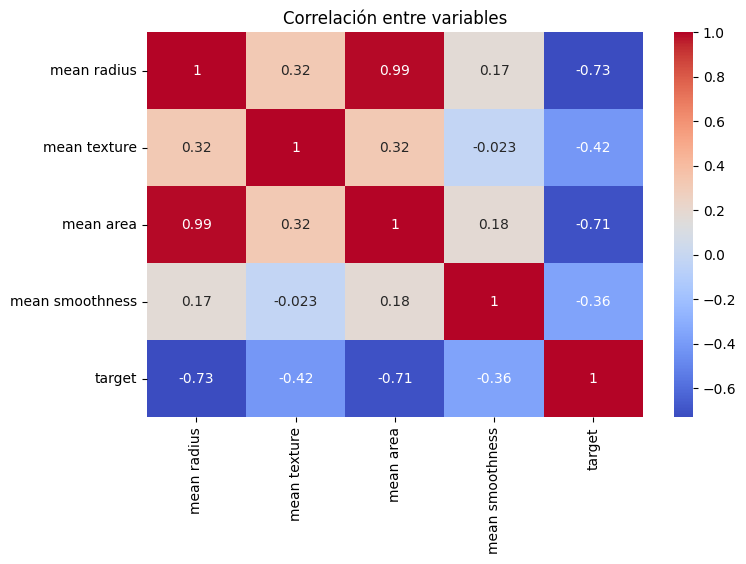

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# Distribución de las clases
sns.countplot(data=df_limpio, x="target")
plt.title("Distribución de clases")
plt.xlabel("Clase (0 = maligno, 1 = benigno)")
plt.ylabel("Cantidad")
plt.show()

# Correlación entre variables seleccionadas
columnas = ["mean radius", "mean texture", "mean area",
            "mean smoothness", "target"]

plt.figure(figsize=(8, 5))
sns.heatmap(df_limpio[columnas].corr(), annot=True, cmap="coolwarm")
plt.title("Correlación entre variables")
plt.show()


In [4]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Separar variables y objetivo
X = df_limpio.drop(columns=["target"])
y = df_limpio["target"]

# Dividir datos: 80% entrenamiento, 20% prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Definir modelos
modelos = {
    "Regresión logística": (
        Pipeline([
            ("escalado", StandardScaler()),
            ("modelo", LogisticRegression(max_iter=2000))
        ]),
        {"modelo__C": [0.1, 1, 10]}
    ),
    "Random Forest": (
        Pipeline([
            ("modelo", RandomForestClassifier(random_state=42))
        ]),
        {
            "modelo__n_estimators": [50, 100],
            "modelo__max_depth": [None, 5, 10]
        }
    )
}


In [5]:
# Entrenar con validación cruzada
resultados = {}

for nombre, (modelo, parametros) in modelos.items():
    busqueda = GridSearchCV(
        modelo, parametros, cv=5, scoring="f1", n_jobs=-1
    )
    busqueda.fit(X_train, y_train)
    resultados[nombre] = busqueda

    print(nombre)
    print("Mejores parámetros:", busqueda.best_params_)
    print("F1 validación cruzada:", round(busqueda.best_score_, 4))
    print()


Regresión logística
Mejores parámetros: {'modelo__C': 0.1}
F1 validación cruzada: 0.9845

Random Forest
Mejores parámetros: {'modelo__max_depth': None, 'modelo__n_estimators': 100}
F1 validación cruzada: 0.9634



In [6]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

# Evaluar los modelos sobre datos de prueba
metricas = []

for nombre, busqueda in resultados.items():
    modelo = busqueda.best_estimator_
    pred = modelo.predict(X_test)
    prob = modelo.predict_proba(X_test)[:, 1]

    metricas.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, prob)
    })

tabla_metricas = pd.DataFrame(metricas)
display(tabla_metricas.round(4))


,Modelo,Accuracy,Precision,Recall,F1,ROC-AUC
0,Regresión logística,0.9737,0.9726,0.9861,0.9793,0.9957
1,Random Forest,0.9561,0.9589,0.9722,0.9655,0.9937


In [7]:
!pip -q install mlflow


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 2.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 2.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 126.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 128.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 94.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 21.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 15.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 11.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 23.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 14.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 10.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [11]:
import mlflow
import mlflow.sklearn
import os

# Permitir el uso del backend de sistema de archivos local (evita la excepción de mantenimiento)
os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"

# Configurar MLflow
mlflow.set_tracking_uri("file://" + os.path.abspath("mlruns"))
mlflow.set_experiment("Actividad5_Clasificacion")

# Registrar modelos y resultados
for nombre, busqueda in resultados.items():
    with mlflow.start_run(run_name=nombre):

        # Registrar hiperparámetros
        mlflow.log_params(busqueda.best_params_)

        # Registrar métricas
        fila = tabla_metricas[
            tabla_metricas["Modelo"] == nombre
        ].iloc[0]

        for metrica in ["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]:
            mlflow.log_metric(metrica, float(fila[metrica]))

        mlflow.log_metric("F1_CV", float(busqueda.best_score_))

        # Registrar modelo entrenado indicando que confiamos en los tipos de Árboles de scikit-learn
        mlflow.sklearn.log_model(
            sk_model=busqueda.best_estimator_,
            artifact_path="modelo",
            skops_trusted_types=["sklearn.tree._tree.Tree"]
        )

        # Registrar configuración de validación
        mlflow.set_tag("validacion", "GridSearchCV_5fold")
        mlflow.set_tag("dataset", "Breast_Cancer_Wisconsin")

        print("Registrado:", nombre)

print("Experimentos guardados correctamente.")

2026/10/19 06:39:29 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/10/19 06:39:33 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Registrado: Regresión logística
Registrado: Random Forest
Experimentos guardados correctamente.


In [12]:
# Consultar experimentos registrados
experimentos = mlflow.search_runs(
    experiment_names=["Actividad5_Clasificacion"]
)

columnas = [
    "tags.mlflow.runName",
    "metrics.Accuracy",
    "metrics.Precision",
    "metrics.Recall",
    "metrics.F1",
    "metrics.ROC-AUC",
    "metrics.F1_CV"
]

display(experimentos[columnas].round(4))

,tags.mlflow.runName,metrics.Accuracy,metrics.Precision,metrics.Recall,metrics.F1,metrics.ROC-AUC,metrics.F1_CV
0,Random Forest,0.9561,0.9589,0.9722,0.9655,0.9937,0.9634
1,Regresión logística,0.9737,0.9726,0.9861,0.9793,0.9957,0.9845
2,Random Forest,0.9561,0.9589,0.9722,0.9655,0.9937,0.9634
3,Regresión logística,0.9737,0.9726,0.9861,0.9793,0.9957,0.9845


In [13]:
from google.colab import output

# Iniciar servidor MLflow
get_ipython().system_raw(
    "mlflow ui --backend-store-uri "
    + os.path.abspath("mlruns")
    + " --host 0.0.0.0 --port 5000 > /tmp/mlflow.log 2>&1 &"
)



<IPython.core.display.Javascript object>

In [17]:
print(open("/tmp/mlflow_5001.log").read()[-2000:])

Registry store URI not provided. Using backend store URI.
[MLflow] Security middleware enabled. Allowed hosts: *.
2026/10/19 06:42:12 WARNING mlflow.server: MLflow job execution requirements not met (MLflow job backend requires a database backend store URI but got /content/mlruns). Server will start without job execution support. Errors will be surfaced at job invocation time.
2026/10/19 06:42:12 INFO:     Uvicorn running on http://0.0.0.0:5001 (Press CTRL+C to quit)
2026/10/19 06:42:12 INFO:     Started parent process [3072]



In [18]:

from google.colab import output

output.serve_kernel_port_as_iframe(5001, height=600)


<IPython.core.display.Javascript object>

In [21]:
# Consultar experimentos directamente desde Python
import mlflow

experimentos = mlflow.search_runs(
    experiment_names=["Actividad5_Clasificacion"]
)

print("Experimentos encontrados:", len(experimentos))

display(experimentos[[
    "tags.mlflow.runName",
    "metrics.Accuracy",
    "metrics.F1",
    "metrics.ROC-AUC"
]])

Experimentos encontrados: 4


,tags.mlflow.runName,metrics.Accuracy,metrics.F1,metrics.ROC-AUC
0,Random Forest,0.956140,0.965517,0.993717
1,Regresión logística,0.973684,0.979310,0.995701
2,Random Forest,0.956140,0.965517,0.993717
3,Regresión logística,0.973684,0.979310,0.995701


In [23]:
import mlflow
import pandas as pd

# Consultar experimentos registrados
df_mlflow = mlflow.search_runs(
    experiment_names=["Actividad5_Clasificacion"]
)

# Seleccionar métricas y eliminar ejecuciones duplicadas
columnas = [
    "tags.mlflow.runName",
    "metrics.Accuracy",
    "metrics.Precision",
    "metrics.Recall",
    "metrics.F1",
    "metrics.ROC-AUC",
    "metrics.F1_CV"
]

comparacion = df_mlflow[columnas].drop_duplicates(
    subset=["tags.mlflow.runName"]
)

comparacion = comparacion.rename(
    columns={"tags.mlflow.runName": "Modelo"}
)

display(comparacion.round(4))

,Modelo,metrics.Accuracy,metrics.Precision,metrics.Recall,metrics.F1,metrics.ROC-AUC,metrics.F1_CV
0,Random Forest,0.9561,0.9589,0.9722,0.9655,0.9937,0.9634
1,Regresión logística,0.9737,0.9726,0.9861,0.9793,0.9957,0.9845


In [24]:
# Mostrar ejecuciones y artefactos registrados
for _, run in df_mlflow.drop_duplicates(
    subset=["tags.mlflow.runName"]
).iterrows():

    run_id = run["run_id"]
    info = mlflow.get_run(run_id)

    print("\nModelo:", info.data.tags.get("mlflow.runName"))
    print("Parámetros:", info.data.params)
    print("Artefactos:", [
        a.path for a in mlflow.artifacts.list_artifacts(
            run_id=run_id
        )
    ])


Modelo: Random Forest
Parámetros: {'modelo__max_depth': 'None', 'modelo__n_estimators': '100'}
Artefactos: []

Modelo: Regresión logística
Parámetros: {'modelo__C': '0.1'}
Artefactos: []


In [26]:
from mlflow import MlflowClient

cliente = MlflowClient()

# Obtener identificador del experimento
exp = mlflow.get_experiment_by_name("Actividad5_Clasificacion")

# Consultar modelos guardados
modelos_guardados = cliente.search_logged_models(
    experiment_ids=[exp.experiment_id]
)

print("Total de modelos guardados:", len(modelos_guardados))

for modelo in modelos_guardados:
    print("Modelo ID:", modelo.model_id)

Total de modelos guardados: 4
Modelo ID: m-1410fe0fc1c84d00bc300460bbfb5efb
Modelo ID: m-4787459b9ce44ccdafd7b41066a66192
Modelo ID: m-920260869d074b07995964ab69a9ea9d
Modelo ID: m-e937d7ec20e146c39dafb93f4f83a58c


In [27]:
import os

# Crear estructura del proyecto
os.makedirs("Actividad5/datos/datos_ini", exist_ok=True)
os.makedirs("Actividad5/datos/datos_limp", exist_ok=True)
os.makedirs("Actividad5/fuentes", exist_ok=True)

# Copiar datasets
df.to_csv("Actividad5/datos/datos_ini/dataset.csv", index=False)
df_limpio.to_csv("Actividad5/datos/datos_limp/dataset_limpio.csv", index=False)

print("Carpetas y datasets creados correctamente.")

Carpetas y datasets creados correctamente.


In [28]:
codigo = '''
import pandas as pd

def limpiar_datos(ruta):
    df = pd.read_csv(ruta)
    df = df.drop_duplicates()
    df = df.dropna()
    return df
'''

with open("Actividad5/fuentes/datos_prep.py", "w") as archivo:
    archivo.write(codigo)

print("datos_prep.py creado.")

datos_prep.py creado.


In [29]:
codigo = '''
import os
import pandas as pd
import mlflow
import mlflow.sklearn
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

# Cargar datos limpios
ruta = os.path.join("datos", "datos_limp", "dataset_limpio.csv")
df = pd.read_csv(ruta)

X = df.drop(columns=["target"])
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Definir modelos y parámetros
modelos = {
    "Regresión logística": (
        Pipeline([
            ("escalado", StandardScaler()),
            ("modelo", LogisticRegression(max_iter=2000))
        ]),
        {"modelo__C": [0.1, 1, 10]}
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=42),
        {"n_estimators": [50, 100], "max_depth": [None, 5, 10]}
    )
}

# Configurar MLflow
mlflow.set_tracking_uri("file://" + os.path.abspath("mlruns"))
mlflow.set_experiment("Actividad5_Clasificacion")

# Entrenar y registrar
for nombre, (modelo, parametros) in modelos.items():
    busqueda = GridSearchCV(
        modelo, parametros, cv=5, scoring="f1", n_jobs=-1
    )
    busqueda.fit(X_train, y_train)

    mejor = busqueda.best_estimator_
    pred = mejor.predict(X_test)
    prob = mejor.predict_proba(X_test)[:, 1]

    with mlflow.start_run(run_name=nombre):
        mlflow.log_params(busqueda.best_params_)
        mlflow.log_metric("Accuracy", accuracy_score(y_test, pred))
        mlflow.log_metric("F1", f1_score(y_test, pred))
        mlflow.log_metric("ROC-AUC", roc_auc_score(y_test, prob))
        mlflow.log_metric("F1_CV", busqueda.best_score_)
        mlflow.sklearn.log_model(mejor, name="modelo")

    print(nombre, "registrado correctamente.")
'''

with open("Actividad5/fuentes/train.py", "w") as archivo:
    archivo.write(codigo)

print("train.py creado.")

train.py creado.


In [30]:
readme = """# Actividad 5 - Gestión de proyectos de IA

## Objetivo
Comparar dos modelos de clasificación mediante GridSearchCV
y registrar sus resultados utilizando MLflow.

## Dataset
Breast Cancer Wisconsin, disponible en Scikit-learn.
569 registros, 30 características y una variable objetivo.

## Modelos
- Regresión logística
- Random Forest

## Metodología
1. Limpieza de datos.
2. División de entrenamiento y prueba (80/20).
3. Validación cruzada de 5 particiones.
4. Optimización mediante GridSearchCV.
5. Evaluación y seguimiento con MLflow.

## Reproducción
Instalar pandas, scikit-learn y mlflow.

Desde la carpeta Actividad5 ejecutar:
python fuentes/train.py

Los resultados se registran en la carpeta mlruns.
"""

changelog = """# CHANGELOG

## Versión 1.0.0
- Incorporación del dataset original.
- Limpieza y eliminación de duplicados.
- Entrenamiento de regresión logística y random forest.
- Optimización mediante GridSearchCV.
- Registro de métricas y modelos en MLflow.
- Comparación de resultados.
"""

with open("Actividad5/README.md", "w") as archivo:
    archivo.write(readme)

with open("Actividad5/CHANGELOG.md", "w") as archivo:
    archivo.write(changelog)

print("README y CHANGELOG creados.")

README y CHANGELOG creados.


In [31]:
# Mostrar archivos del proyecto
for carpeta, subcarpetas, archivos in os.walk("Actividad5"):
    print(carpeta)
    for archivo in archivos:
        print("  -", archivo)

Actividad5
  - README.md
  - CHANGELOG.md
Actividad5/fuentes
  - datos_prep.py
  - train.py
Actividad5/datos
Actividad5/datos/datos_ini
  - dataset.csv
Actividad5/datos/datos_limp
  - dataset_limpio.csv
